In [11]:
import json
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

THU_MUC_GOC = Path("..").resolve()
sys.path.append(str(THU_MUC_GOC))
from data.preprocessor.bo_loc_anh import kiem_tra_dinh_dang_anh

DATA_GOC = THU_MUC_GOC / "data" / "raw"
DATA_DA_XU_LI =THU_MUC_GOC / "data" / "processed"
THU_MUC_MODEL =THU_MUC_GOC / "model"
THU_MUC_MODEL.mkdir(parents=True, exist_ok=True)


In [12]:
records = []
corrupted_files = []
lop = sorted([d.name for d in DATA_GOC.iterdir() if d.is_dir()])
print(lop)
for idx_label, ten_lop in enumerate(lop):
    thu_muc_lop = DATA_GOC / ten_lop
    for anh in thu_muc_lop.iterdir():
        if not anh.is_file():
            continue
        if kiem_tra_dinh_dang_anh(anh):
            records.append({
                "filepath": anh,
                "label_name": ten_lop,
                "label_idx": idx_label,
            })
        else:
            corrupted_files.append(str(anh))

['Huu_Co', 'Tai_Che', 'Vo_Co']


In [13]:
print(f"Ảnh hợp lệ: {len(records)} | Ảnh lỗi: {len(corrupted_files)}")

Ảnh hợp lệ: 16110 | Ảnh lỗi: 0


In [14]:
THU_MUC_REPORT = THU_MUC_GOC / "report"
THU_MUC_REPORT.mkdir(parents = True, exist_ok = True)

df = pd.DataFrame(records)
so_luong = df["label_name"].value_counts()
print("Số lượng ảnh từng lớp:")
print(so_luong)
print("\nTỷ lệ (%):")
print((so_luong / len(df) * 100).round(2))

Số lượng ảnh từng lớp:
label_name
Tai_Che    7010
Huu_Co     4550
Vo_Co      4550
Name: count, dtype: int64

Tỷ lệ (%):
label_name
Tai_Che    43.51
Huu_Co     28.24
Vo_Co      28.24
Name: count, dtype: float64


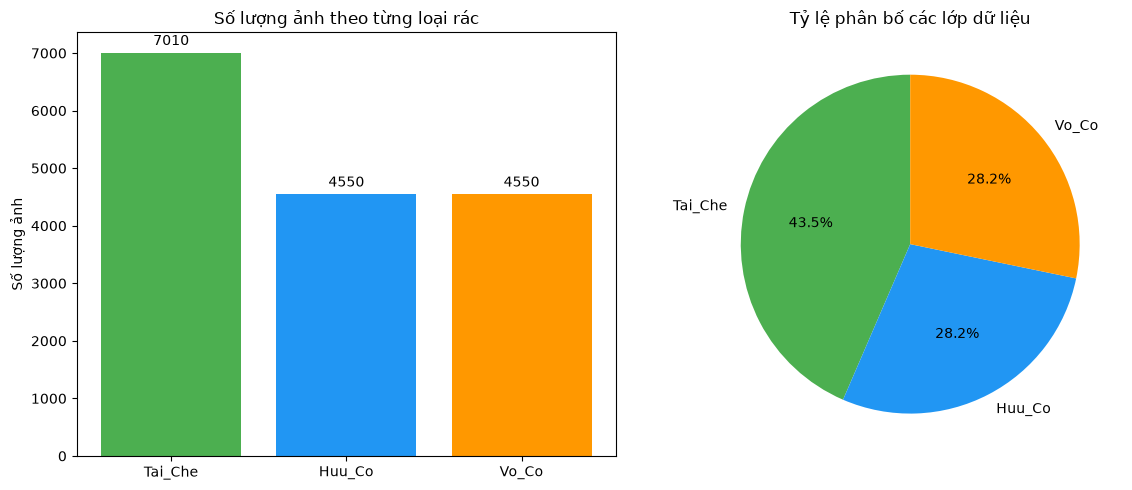

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
mau_sac = ["#4CAF50", "#2196F3", "#FF9800"]

bars = axes[0].bar(so_luong.index, so_luong.values, color=mau_sac[:len(so_luong)])
axes[0].set_title("Số lượng ảnh theo từng loại rác")
axes[0].set_ylabel("Số lượng ảnh")
axes[0].bar_label(bars, padding=3)

axes[1].pie(
    so_luong.values,
    labels=so_luong.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=mau_sac[:len(so_luong)],
)
axes[1].set_title("Tỷ lệ phân bố các lớp dữ liệu")

plt.tight_layout()
plt.savefig(THU_MUC_REPORT / "phan_bo_du_lieu.png", dpi=150)
plt.show()

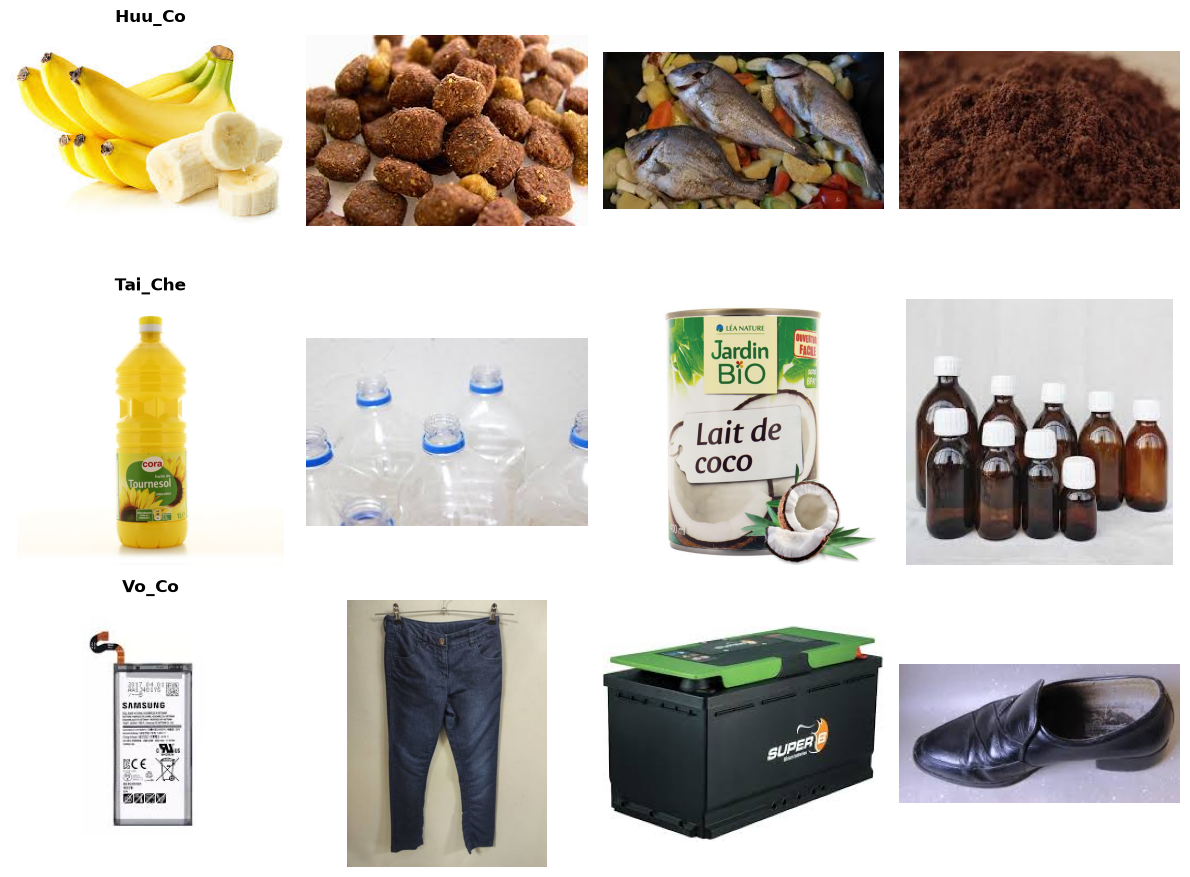

In [16]:
from PIL import Image

so_anh_moi_lop = 4
fig, axes = plt.subplots(len(lop), so_anh_moi_lop, figsize=(12, 3 * len(lop)))

for hang, ten_lop in enumerate(lop):
    anh_mau = df[df["label_name"] == ten_lop].sample(so_anh_moi_lop, random_state=42)
    for cot, (_, row) in enumerate(anh_mau.iterrows()):
        with Image.open(row["filepath"]) as img:
            axes[hang, cot].imshow(img.convert("RGB"))
        axes[hang, cot].axis("off")
        if cot == 0:
            axes[hang, cot].set_title(ten_lop, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(THU_MUC_REPORT / "anh_mau_tung_lop.png", dpi=150)
plt.show()

In [17]:

labels_map = {str(idx): name for idx, name in enumerate(lop)}
with open(THU_MUC_MODEL / "labels.json", "w", encoding="utf-8") as f:
    json.dump(labels_map, f, ensure_ascii=False, indent=2)
print("Đã lưu labels.json:", labels_map)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label_idx"],
    random_state=42,
)

if DATA_DA_XU_LI.exists():
    shutil.rmtree(DATA_DA_XU_LI)

def xuat_tap_du_lieu(split_df, ten_tap):
    for _, row in split_df.iterrows():
        thu_muc_dich = DATA_DA_XU_LI / ten_tap / row["label_name"]
        thu_muc_dich.mkdir(parents=True, exist_ok=True)
        shutil.copy2(row["filepath"], thu_muc_dich / row["filepath"].name)

print("Đang copy ảnh sang data/processed/...")
xuat_tap_du_lieu(train_df, "train")
xuat_tap_du_lieu(test_df, "test")

print(f"Hoàn tất! Train: {len(train_df)} ảnh | Test: {len(test_df)} ảnh")
print("\nPhân bố tập Train:")
print(train_df["label_name"].value_counts())
print("\nPhân bố tập Test:")
print(test_df["label_name"].value_counts())

Đã lưu labels.json: {'0': 'Huu_Co', '1': 'Tai_Che', '2': 'Vo_Co'}
Đang copy ảnh sang data/processed/...
Hoàn tất! Train: 12888 ảnh | Test: 3222 ảnh

Phân bố tập Train:
label_name
Tai_Che    5608
Vo_Co      3640
Huu_Co     3640
Name: count, dtype: int64

Phân bố tập Test:
label_name
Tai_Che    1402
Vo_Co       910
Huu_Co      910
Name: count, dtype: int64
